<a href="https://colab.research.google.com/github/aibakalfaqeeh73-hub/colab-demo/blob/main/dana_bakery_langgraph.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dana's Bakery: order system with LangGraph

This notebook implements the homework specification as a deterministic workflow. It uses fixed opening inventory for each independent order, no LLM calls, and no external API.

In [1]:
!pip -q install -U langgraph

from typing import Annotated, Literal, TypedDict
import operator
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

print('LangGraph is ready')

LangGraph is ready


## Rules and graph state

Each invocation starts from the same opening inventory. Substitution keeps the requested quantity and follows the specified chain. The state carries order details, calculation fields, and an append-only execution diary.

In [2]:
MENU = {
    "challah": {"price": 18, "stock": 10},
    "babka": {"price": 45, "stock": 0},
    "rugelach": {"price": 30, "stock": 3},
    "sourdough": {"price": 25, "stock": 4},
}
SUBSTITUTES = {
    "babka": ["rugelach", "sourdough", "challah"],
    "rugelach": ["sourdough", "challah"],
    "sourdough": ["challah"],
    "challah": [],
}
REQUIRED_OUTPUT_KEYS = {"status", "item", "delivery", "total", "message", "steps"}

class OrderState(TypedDict, total=False):
    item: str | None
    quantity: int
    day: str
    city: str
    original_item: str
    delivery: str
    status: str
    total: float
    message: str
    steps: Annotated[list[str], operator.add]
    attempts: int
    stock_available: bool
    baked_goods_subtotal: float
    delivery_fee: int
    discount: float
    invalid_reason: str

def node_update(name: str, **updates) -> dict:
    """Return a node update that appends exactly one diary entry."""
    updates["steps"] = [name]
    return updates


## Nodes and routing

Invalid orders go directly to rejection. A valid order checks stock, then tries up to two substitutes. Accepted orders set delivery, calculate the discount on baked goods only, and generate a customer reply. Every executed node appends its own name to `steps`.

In [3]:
def validate_order(state: OrderState) -> dict:
    raw_item = state.get("item")
    item = raw_item.strip().lower() if isinstance(raw_item, str) else ""
    raw_city = state.get("city", "")
    city = raw_city.strip() if isinstance(raw_city, str) else ""
    day_value = state.get("day", "")
    day = day_value.strip() if isinstance(day_value, str) else ""
    quantity = state.get("quantity")

    updates = {
        "original_item": item,
        "city": city,
        "day": day,
        "delivery": "delivery" if city.casefold() == "jerusalem" else "pickup",
        "attempts": 0,
    }
    if item not in MENU:
        updates["invalid_reason"] = "I could not understand which menu item you wanted."
    elif isinstance(quantity, bool) or not isinstance(quantity, int) or quantity <= 0:
        updates["invalid_reason"] = "I could not understand the quantity. Please enter a positive whole number."
    else:
        updates["item"] = item
    return node_update("validate_order", **updates)

def route_after_validation(state: OrderState) -> Literal["reject_order", "check_inventory"]:
    return "reject_order" if state.get("invalid_reason") else "check_inventory"

def check_inventory(state: OrderState) -> dict:
    item = state["item"]
    quantity = state["quantity"]
    available = MENU[item]["stock"] >= quantity
    return node_update("check_inventory", stock_available=available)

def route_after_inventory(state: OrderState) -> Literal["set_delivery", "try_next_substitute", "reject_order"]:
    if state["stock_available"]:
        return "set_delivery"
    candidates = SUBSTITUTES[state["original_item"]]
    attempts = state.get("attempts", 0)
    if attempts < 2 and attempts < len(candidates):
        return "try_next_substitute"
    return "reject_order"

def try_next_substitute(state: OrderState) -> dict:
    candidates = SUBSTITUTES[state["original_item"]]
    attempt_index = state.get("attempts", 0)
    candidate = candidates[attempt_index]
    return node_update(
        "try_next_substitute",
        item=candidate,
        attempts=attempt_index + 1,
    )

def set_delivery(state: OrderState) -> dict:
    city = state.get("city", "")
    delivery = "delivery" if city.casefold() == "jerusalem" else "pickup"
    fee = 20 if delivery == "delivery" else 0
    return node_update("set_delivery", delivery=delivery, delivery_fee=fee)

def calculate_total(state: OrderState) -> dict:
    subtotal = MENU[state["item"]]["price"] * state["quantity"]
    discount = 0.15 * subtotal if subtotal > 150 and state.get("day", "").casefold() != "friday" else 0.0
    total = round(subtotal - discount + state.get("delivery_fee", 0), 2)
    return node_update(
        "calculate_total",
        status="accepted",
        baked_goods_subtotal=subtotal,
        discount=discount,
        total=total,
    )

def write_customer_message(state: OrderState) -> dict:
    sold_item = state["item"]
    requested_item = state["original_item"]
    quantity = state["quantity"]
    if sold_item == requested_item:
        opening = f"Thanks for your order of {quantity} {sold_item}."
    else:
        opening = (f"Thanks for your order. We are out of {requested_item}, "
                   f"so we will prepare {quantity} {sold_item} instead.")
    if state["delivery"] == "delivery":
        fulfillment = "We will deliver it in Jerusalem."
    elif state.get("city", ""):
        fulfillment = "We cannot deliver outside Jerusalem, so we switched your order to pickup."
    else:
        fulfillment = "Your order is set for pickup at the bakery."
    return node_update(
        "write_customer_message",
        message=f"{opening} {fulfillment} Your total is {state['total']:.2f} ILS.",
    )

def reject_order(state: OrderState) -> dict:
    reason = state.get("invalid_reason")
    if not reason:
        reason = "We could not fulfill the requested quantity or the available alternatives."
    return node_update(
        "reject_order",
        status="rejected",
        item=None,
        delivery=state.get("delivery", "pickup"),
        total=0,
        message=f"Sorry, {reason} We have cancelled the order.",
    )


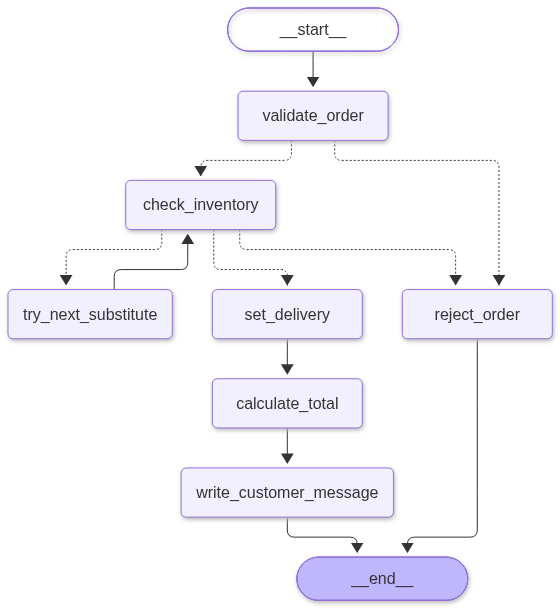

In [4]:
builder = StateGraph(OrderState)
builder.add_node("validate_order", validate_order)
builder.add_node("check_inventory", check_inventory)
builder.add_node("try_next_substitute", try_next_substitute)
builder.add_node("set_delivery", set_delivery)
builder.add_node("calculate_total", calculate_total)
builder.add_node("write_customer_message", write_customer_message)
builder.add_node("reject_order", reject_order)

builder.add_edge(START, "validate_order")
builder.add_conditional_edges("validate_order", route_after_validation)
builder.add_conditional_edges("check_inventory", route_after_inventory)
builder.add_edge("try_next_substitute", "check_inventory")
builder.add_edge("set_delivery", "calculate_total")
builder.add_edge("calculate_total", "write_customer_message")
builder.add_edge("write_customer_message", END)
builder.add_edge("reject_order", END)
graph = builder.compile()

# Required LangGraph drawing. In Colab this displays the rendered graph image.
display(Image(graph.get_graph().draw_mermaid_png()))

## Test orders

The tests below cover invalid product and quantity, direct sale, both successful substitution positions, cancellation after failed alternatives, the end of the substitution chain, Jerusalem delivery, out-of-Jerusalem pickup, the discount threshold, and Friday's discount exception. Each assertion checks the complete output contract and the expected path.

In [5]:
tests = [
    {"name": "unknown product", "order": {"item": "pizza", "quantity": 1, "day": "Thursday", "city": ""},
     "status": "rejected", "item": None, "delivery": "pickup", "total": 0, "path": ["validate_order", "reject_order"]},
    {"name": "invalid quantity", "order": {"item": "challah", "quantity": 0, "day": "Thursday", "city": "Jerusalem"},
     "status": "rejected", "item": None, "delivery": "delivery", "total": 0, "path": ["validate_order", "reject_order"]},
    {"name": "direct Jerusalem order", "order": {"item": "sourdough", "quantity": 2, "day": "Thursday", "city": "Jerusalem"},
     "status": "accepted", "item": "sourdough", "delivery": "delivery", "total": 70, "path": ["validate_order", "check_inventory", "set_delivery", "calculate_total", "write_customer_message"]},
    {"name": "first substitute succeeds", "order": {"item": "babka", "quantity": 2, "day": "Thursday", "city": "Jerusalem"},
     "status": "accepted", "item": "rugelach", "delivery": "delivery", "total": 80, "path": ["validate_order", "check_inventory", "try_next_substitute", "check_inventory", "set_delivery", "calculate_total", "write_customer_message"]},
    {"name": "second substitute succeeds", "order": {"item": "babka", "quantity": 4, "day": "Thursday", "city": "Jerusalem"},
     "status": "accepted", "item": "sourdough", "delivery": "delivery", "total": 120, "path": ["validate_order", "check_inventory", "try_next_substitute", "check_inventory", "try_next_substitute", "check_inventory", "set_delivery", "calculate_total", "write_customer_message"]},
    {"name": "discount above threshold", "order": {"item": "challah", "quantity": 9, "day": "Thursday", "city": "Jerusalem"},
     "status": "accepted", "item": "challah", "delivery": "delivery", "total": 157.7, "path": ["validate_order", "check_inventory", "set_delivery", "calculate_total", "write_customer_message"]},
    {"name": "Friday receives no discount", "order": {"item": "challah", "quantity": 9, "day": "Friday", "city": ""},
     "status": "accepted", "item": "challah", "delivery": "pickup", "total": 162, "path": ["validate_order", "check_inventory", "set_delivery", "calculate_total", "write_customer_message"]},
    {"name": "cancel after two failed substitutes", "order": {"item": "babka", "quantity": 11, "day": "Monday", "city": "Jerusalem"},
     "status": "rejected", "item": None, "delivery": "delivery", "total": 0, "path": ["validate_order", "check_inventory", "try_next_substitute", "check_inventory", "try_next_substitute", "check_inventory", "reject_order"]},
    {"name": "substitution chain ends early", "order": {"item": "sourdough", "quantity": 11, "day": "Monday", "city": ""},
     "status": "rejected", "item": None, "delivery": "pickup", "total": 0, "path": ["validate_order", "check_inventory", "try_next_substitute", "check_inventory", "reject_order"]},
    {"name": "outside Jerusalem switches to pickup", "order": {"item": "rugelach", "quantity": 2, "day": "Friday", "city": "Tel Aviv"},
     "status": "accepted", "item": "rugelach", "delivery": "pickup", "total": 60, "path": ["validate_order", "check_inventory", "set_delivery", "calculate_total", "write_customer_message"]},
]

for case in tests:
    result = graph.invoke(case["order"])
    missing = REQUIRED_OUTPUT_KEYS - result.keys()
    assert not missing, f"{case['name']}: missing keys {missing}"
    assert result["status"] == case["status"], case["name"]
    assert result["item"] == case["item"], case["name"]
    assert result["delivery"] == case["delivery"], case["name"]
    assert result["total"] == case["total"], (case["name"], result["total"])
    assert result["steps"] == case["path"], (case["name"], result["steps"])
    assert isinstance(result["message"], str) and result["message"].strip(), case["name"]
    if case["name"] == "outside Jerusalem switches to pickup":
        assert "switched your order to pickup" in result["message"]
    print(f"PASS: {case['name']} | {result['status']} | item={result['item']} | delivery={result['delivery']} | total={result['total']} ILS")

print(f"\nAll {len(tests)} order tests passed.")

PASS: unknown product | rejected | item=None | delivery=pickup | total=0 ILS
PASS: invalid quantity | rejected | item=None | delivery=delivery | total=0 ILS
PASS: direct Jerusalem order | accepted | item=sourdough | delivery=delivery | total=70.0 ILS
PASS: first substitute succeeds | accepted | item=rugelach | delivery=delivery | total=80.0 ILS
PASS: second substitute succeeds | accepted | item=sourdough | delivery=delivery | total=120.0 ILS
PASS: discount above threshold | accepted | item=challah | delivery=delivery | total=157.7 ILS
PASS: Friday receives no discount | accepted | item=challah | delivery=pickup | total=162.0 ILS
PASS: cancel after two failed substitutes | rejected | item=None | delivery=delivery | total=0 ILS
PASS: substitution chain ends early | rejected | item=None | delivery=pickup | total=0 ILS
PASS: outside Jerusalem switches to pickup | accepted | item=rugelach | delivery=pickup | total=60.0 ILS

All 10 order tests passed.
